In [ ]:
from google.colab import files

uploaded = files.upload()

Saving weatherAUS.csv to weatherAUS.csv


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load dataset
df = pd.read_csv("weatherAUS.csv")

print("Original Dataset Shape:", df.shape)

# Remove duplicate rows
print("Duplicate Rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Remove rows where target is missing
df = df.dropna(subset=["RainTomorrow"])

# Input features
features = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "Evaporation",
    "Sunshine",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
    "Humidity9am",
    "Humidity3pm",
    "Pressure9am",
    "Pressure3pm",
    "Cloud9am",
    "Cloud3pm",
    "Temp9am",
    "Temp3pm",
    "RainToday"
]

X = df[features]
y = df["RainTomorrow"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("\nAfter Preprocessing:")
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Original Dataset Shape: (145460, 23)
Duplicate Rows: 0

After Preprocessing:
Training Shape: (113754, 18)
Testing Shape: (28439, 18)

Target Distribution:
RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


Logistic Regression Accuracy:
84.44%

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.95      0.90     22064
         Yes       0.73      0.49      0.59      6375

    accuracy                           0.84     28439
   macro avg       0.80      0.72      0.74     28439
weighted avg       0.83      0.84      0.83     28439


Confusion Matrix:
[[20888  1176]
 [ 3249  3126]]


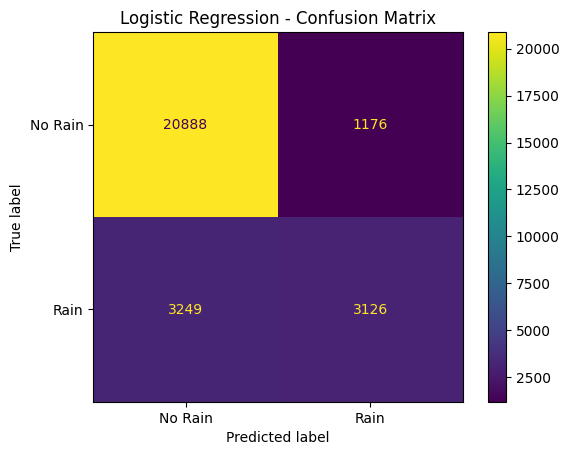

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions on test data
y_pred = model.predict(X_test_processed)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:")
print(f"{accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Rain", "Rain"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
import joblib

# Save trained Logistic Regression model
joblib.dump(model, "weather_logistic_model.pkl")

# Save preprocessing pipeline
joblib.dump(preprocessor, "weather_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [ ]:
import gradio as gr
import pandas as pd

def predict_weather(
    MinTemp,
    MaxTemp,
    Rainfall,
    Evaporation,
    Sunshine,
    WindGustSpeed,
    WindSpeed9am,
    WindSpeed3pm,
    Humidity9am,
    Humidity3pm,
    Pressure9am,
    Pressure3pm,
    Cloud9am,
    Cloud3pm,
    Temp9am,
    Temp3pm,
    RainToday
):

    # Create DataFrame
    new_weather = pd.DataFrame([{
        "MinTemp": MinTemp,
        "MaxTemp": MaxTemp,
        "Rainfall": Rainfall,
        "Evaporation": Evaporation,
        "Sunshine": Sunshine,
        "WindGustSpeed": WindGustSpeed,
        "WindSpeed9am": WindSpeed9am,
        "WindSpeed3pm": WindSpeed3pm,
        "Humidity9am": Humidity9am,
        "Humidity3pm": Humidity3pm,
        "Pressure9am": Pressure9am,
        "Pressure3pm": Pressure3pm,
        "Cloud9am": Cloud9am,
        "Cloud3pm": Cloud3pm,
        "Temp9am": Temp9am,
        "Temp3pm": Temp3pm,
        "RainToday": RainToday
    }])

    # Apply same preprocessing used during training
    new_weather_processed = preprocessor.transform(new_weather)

    # Prediction
    prediction = model.predict(new_weather_processed)[0]

    # Probability
    probabilities = model.predict_proba(new_weather_processed)[0]

    no_rain_probability = probabilities[
        list(model.classes_).index("No")
    ] * 100

    rain_probability = probabilities[
        list(model.classes_).index("Yes")
    ] * 100

    result = f"Prediction: {prediction}"

    probability_result = (
        f"No Rain: {no_rain_probability:.2f}%\n"
        f"Rain: {rain_probability:.2f}%"
    )

    return result, probability_result


demo = gr.Interface(
    fn=predict_weather,

    inputs=[
        gr.Number(label="Minimum Temperature (°C)", value=15),
        gr.Number(label="Maximum Temperature (°C)", value=25),
        gr.Number(label="Rainfall (mm)", value=0),
        gr.Number(label="Evaporation", value=5),
        gr.Number(label="Sunshine (hours)", value=8),
        gr.Number(label="Wind Gust Speed (km/h)", value=35),
        gr.Number(label="Wind Speed 9am (km/h)", value=10),
        gr.Number(label="Wind Speed 3pm (km/h)", value=15),
        gr.Number(label="Humidity 9am (%)", value=60),
        gr.Number(label="Humidity 3pm (%)", value=45),
        gr.Number(label="Pressure 9am (hPa)", value=1015),
        gr.Number(label="Pressure 3pm (hPa)", value=1012),
        gr.Number(label="Cloud 9am (oktas)", value=3),
        gr.Number(label="Cloud 3pm (oktas)", value=4),
        gr.Number(label="Temperature 9am (°C)", value=18),
        gr.Number(label="Temperature 3pm (°C)", value=24),

        gr.Dropdown(
            choices=["No", "Yes"],
            value="No",
            label="Did it rain today?"
        )
    ],

    outputs=[
        gr.Textbox(label="Rain Tomorrow Prediction"),
        gr.Textbox(label="Prediction Probability")
    ],

    title="🌦️ Australia Weather Prediction",
    description="Enter today's weather conditions to predict whether it will rain tomorrow."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f56c51913c7fa14af.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
